In [1]:
import datetime
import pandas as pd
from polygon import RESTClient
from os import listdir

from experiment_main import *
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

API_KEY = "4c0LGxg6J6xl50lzMD9wMyG_pT4o33_I"
client = RESTClient(api_key=API_KEY)

plt.style.use("plot_style.txt")

alphaRange = [
    -0.9,
    -0.8,
    -0.7,
    -0.6,
    -0.5,
    -0.4,
    -0.3,
    -0.2,
    -0.1,
    0,
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
]
gammaRange = [
    1,
    2,
    4,
    10,
    20,
    30,
    40,
    50,
    60,
    70,
    80,
    90,
    100,
    200,
    300,
    400,
    500,
    600,
    700,
    800,
    900,
    1000,
    10000,
    100000,
]
gammaRange_reversed = list(reversed(gammaRange))
gen = [(x, y) for x in alphaRange for y in gammaRange]
histogramList, MACDList, signalLineList = return_macd_lists(alphaRange, gammaRange)

In [2]:
def fetch_stock_data(symbols, start_date, end_date):
    stocks = []

    for symbol in symbols:
        aggs = client.get_aggs(
            symbol,
            1,
            "day",
            start_date,
            end_date,
        )
        df = pd.DataFrame(aggs, columns=["timestamp", "close"])

        # Filter out rows with invalid timestamps
        df = df[df["timestamp"] > 0]

        df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
        df.set_index("timestamp", inplace=True)

        df.rename(columns={"close": symbol}, inplace=True)
        stocks.append(df)

    merged_stocks = pd.concat(stocks, axis=1)
    # merged_stocks.dropna()
    return merged_stocks


def calculate_daily_returns(stock_data):
    daily_returns = stock_data.pct_change().dropna()
    return daily_returns


def compute_correlation_matrix(daily_returns):
    correlation_matrix = daily_returns.corr()
    return correlation_matrix


# def plot_correlation_heatmap(correlation_matrix):
#     plt.figure(figsize=(8, 8))
#     ax = sns.heatmap(
#         correlation_matrix,
#         annot=True,
#         cmap="coolwarm",
#         vmin=-1,
#         vmax=1,
#         square=True,
#         linewidths=0.5,
#         cbar_kws={"shrink": 0.8},
#     )
#     ax.xaxis.tick_top()
#     ax.xaxis.set_label_position("top")
#     plt.title("Correlation Matrix Heatmap", y=1.08)
#     plt.show()

In [3]:
market = "stocks"
MACDparams = (12, 26, 9)
trade_cost = False
timeFormat = "1_day"
prefix = f"./data/{market}/{timeFormat}/"
datafiles = listdir(prefix)
datafiles.remove("meta.us.txt")
datafiles.remove("fb.us.txt")
# makeDataFrame(prefix, datafiles[0], MACDparams, alphaRange, gammaRange)
# datafiles

In [4]:
symbols = sorted([x[:-7].upper() for x in datafiles])
merged_stocks = dict()
merged_daily_returns = dict()
merged_correlation_matrix = dict()

# Date range you are interested in
start_date = "2020-02-06"
end_date = "2025-02-06"
stock_data = fetch_stock_data(symbols, start_date, end_date)
daily_returns = calculate_daily_returns(stock_data)
correlation_matrix = compute_correlation_matrix(daily_returns)

merged_stocks[f"{start_date}_{end_date}"] = stock_data
merged_daily_returns[f"{start_date}_{end_date}"] = daily_returns
merged_correlation_matrix[f"{start_date}_{end_date}"] = correlation_matrix

In [5]:
start_date = "2023-02-06"
end_date = "2024-02-06"
stock_data = fetch_stock_data(symbols, start_date, end_date)
daily_returns = calculate_daily_returns(stock_data)
correlation_matrix = compute_correlation_matrix(daily_returns)

In [6]:
# stock_data['FB']
# stock_data.isnull().any()

In [7]:
dates_list = [
    "2020-02-06",
    "2021-02-06",
    "2022-02-06",
    "2023-02-06",
    "2024-02-06",
    "2025-02-06",
]

for i in range(1, len(dates_list)):
    start_date = dates_list[i - 1]
    end_date = dates_list[i]
    stock_data = fetch_stock_data(symbols, start_date, end_date)
    daily_returns = calculate_daily_returns(stock_data)
    correlation_matrix = compute_correlation_matrix(daily_returns)

    merged_stocks[f"{start_date}_{end_date}"] = stock_data
    merged_daily_returns[f"{start_date}_{end_date}"] = daily_returns
    merged_correlation_matrix[f"{start_date}_{end_date}"] = correlation_matrix

In [8]:
# plot_correlation_heatmap(correlation_matrix)

In [9]:
# data_plot_hourly = merged_correlation_matrix[0]

# timeFormats = ['1_day']
# times_dict = {t: {k: 0 for k in gen} for t in timeFormats}
# for timeFormat in timeFormats:
#     prefix = f"./data/{market}/{timeFormat}/"
#     for tick in datafiles:
#         df = makeDataFrame(prefix, tick, MACDparams, alphaRange, gammaRange)
#         target_cols = [c for c in df.columns if c.endswith("times")]
#         for col in target_cols:
#             target_tuple = (float(col.split()[2]), int(col.split()[4]))
#             times_dict[timeFormat][target_tuple] += int(df[col].iloc[0])

# data_list_hourly = []
# data_list_minutely = []

# for gamma in gammaRange_reversed:
#     inner_hourly = []
#     # inner_minutely = []
#     for alpha in alphaRange:
#         target_tuple = (alpha, gamma)
#         data_list_hourly.append(times_dict["1_day"][target_tuple])
#         # data_list_minutely.append(times_dict["Minutely"][target_tuple])

# hourly_max = max(data_list_hourly)
# norm_hourly_list = [float(i) / hourly_max for i in data_list_hourly]
# data_plot_hourly = np.array(norm_hourly_list).reshape((len(gammaRange), len(alphaRange)))

# minutely_max = max(data_list_minutely)
# norm_minutely_list = [float(i) / minutely_max for i in data_list_minutely]
# data_plot_minutely = np.array(norm_minutely_list).reshape((6, 19))


# for target_tuple in gen:
#     data_list_hourly.append(times_dict['Hourly'][target_tuple])
#     data_list_minutely.append(times_dict['Minutely'][target_tuple])

# hourly_max = max(data_list_hourly)
# norm_hourly_list = [float(i)/hourly_max for i in data_list_hourly]

# minutely_max = max(data_list_minutely)
# norm_minutely_list = [float(i)/minutely_max for i in data_list_minutely]

In [10]:
def heatmap(
    data,
    row_labels,
    col_labels,
    ax=None,
    cbar_kw={},
    cbarlabel="",
    cbar_return=True,
    **kwargs
):
    """
    Create a heatmap from a numpy array and two lists of labels.

    Parameters
    ----------
    data
        A 2D numpy array of shape (M, N).
    row_labels
        A list or array of length M with the labels for the rows.
    col_labels
        A list or array of length N with the labels for the columns.
    ax
        A `matplotlib.axes.Axes` instance to which the heatmap is plotted.  If
        not provided, use current axes or create a new one.  Optional.
    cbar_kw
        A dictionary with arguments to `matplotlib.Figure.colorbar`.  Optional.
    cbarlabel
        The label for the colorbar.  Optional.
    **kwargs
        All other arguments are forwarded to `imshow`.
    """

    if not ax:
        ax = plt.gca()

    # Plot the heatmap
    im = ax.imshow(data, **kwargs)

    # Create colorbar
    # ticks = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
    ticks = [-0.5, 0, 1.0]
    cbar = ax.figure.colorbar(im, ax=ax, ticks=ticks, **cbar_kw)
    cbar.ax.set_yticklabels(
        labels=cbar.ax.get_yticklabels(), color="black", weight="bold"
    )
    # cbar = mpl.colorbar.ColorbarBase(
    #     im, ax=ax, orientation='vertical', norm=plt.Normalize(0,1), **cbar_kw
    # )
    # cbar.set_ticks(ticks)
    # cbar.ax.set_yticklabels(ticks)
    # cbar.ax.set_xticklabels(ticks)
    # cbar.ax.set_ylabel(cbarlabel, rotation=-90, va="bottom")
    # .set_ticklabel

    # Show all ticks and label them with the respective list entries.
    ax.set_xticks(
        range(len(col_labels)),
        labels=col_labels,
        color="black",
        weight="bold",
        ha="right",
        rotation=90,
    )

    ax.set_xticklabels(col_labels, fontsize=5)
    ax.set_yticks(
        range(len(row_labels)), labels=row_labels, color="black", weight="bold"
    )
    ax.set_yticklabels(row_labels, fontsize=5)
    # ax.set_yticklabels(avg_y_ticks, weight='bold', color='black')
    # colorbar.set_ticks(np.linspace(0, ncolors, ncolors))
    # colorbar.set_ticklabels(range(ncolors))

    ax.tick_params(
        axis="both",
        which="both",
        right=False,
        left=True,
        labelleft=True,
        labelright=False,
        top=True,
        bottom=False,
        labeltop=True,
        labelbottom=False,
        length=0,
    )

    # Rotate the tick labels and set their alignment.
    plt.setp(ax.get_xticklabels(), ha="center")

    # Turn spines off and create white grid.
    ax.spines[:].set_visible(False)

    return im, cbar


def annotate_heatmap(
    im,
    data=None,
    valfmt="{x:.2f}",
    textcolors=("black", "black"),
    threshold=None,
    **textkw
):
    """
    A function to annotate a heatmap.

    Parameters
    ----------
    im
        The AxesImage to be labeled.
    data
        Data used to annotate.  If None, the image's data is used.  Optional.
    valfmt
        The format of the annotations inside the heatmap.  This should either
        use the string format method, e.g. "$ {x:.2f}", or be a
        `matplotlib.ticker.Formatter`.  Optional.
    textcolors
        A pair of colors.  The first is used for values below a threshold,
        the second for those above.  Optional.
    threshold
        Value in data units according to which the colors from textcolors are
        applied.  If None (the default) uses the middle of the colormap as
        separation.  Optional.
    **kwargs
        All other arguments are forwarded to each call to `text` used to create
        the text labels.
    """

    if not isinstance(data, (list, np.ndarray)):
        data = im.get_array()

    # Normalize the threshold to the images color range.
    if threshold is not None:
        threshold = im.norm(threshold)
    else:
        threshold = im.norm(data.max()) / 2.0

    # Set default alignment to center, but allow it to be
    # overwritten by textkw.
    kw = dict(horizontalalignment="center", verticalalignment="center")
    kw.update(textkw)

    # Get the formatter in case a string is supplied
    if isinstance(valfmt, str):
        valfmt = mpl.ticker.StrMethodFormatter(valfmt)

    # Loop over the data and create a `Text` for each "pixel".
    # Change the text's color depending on the data.
    texts = []
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            kw.update(color=textcolors[int(im.norm(data[i, j]) > threshold)])
            text = im.axes.text(j, i, valfmt(data[i, j], None), **kw)
            texts.append(text)

    return texts

In [11]:
def plot_daily_return_heatmap(daily_returns, start_date, end_date):

    fig, ax = plt.subplots()

    # Replicate the above example with a different font size and colormap.

    im, cbar = heatmap(
        daily_returns,
        symbols,
        symbols,
        ax=ax,
        cmap="jet",
        cbar_kw={"location": "right"},
    )
    im.set_clim([-0.5, 1])
    for l in cbar.ax.yaxis.get_ticklabels():
        l.set_weight("bold")
        l.set_color("black")
    annotate_heatmap(im, valfmt="{x:.2f}", size=4)

    # Create some new data, give further arguments to imshow (vmin),
    # use an integer format on the annotations and provide some colors.
    # cbarlabel="Something ax2"

    fig.tight_layout()
    # plt.subplots_adjust(wspace=0, hspace=0.35)
    # fig.supylabel('Price ($)', fontweight='bold', color='black', fontsize=8)
    fig.suptitle(
        f"{start_date} to {end_date} Daily Returns Correlations Heatmap",
        x=0.6,
        y=1.01,
        fontweight="bold",
        fontsize=10,
        color="black",
    )
    fig.set_size_inches(10, 5)
    plt.savefig(f"correlations_{start_date}_{end_date}.pdf", bbox_inches="tight")

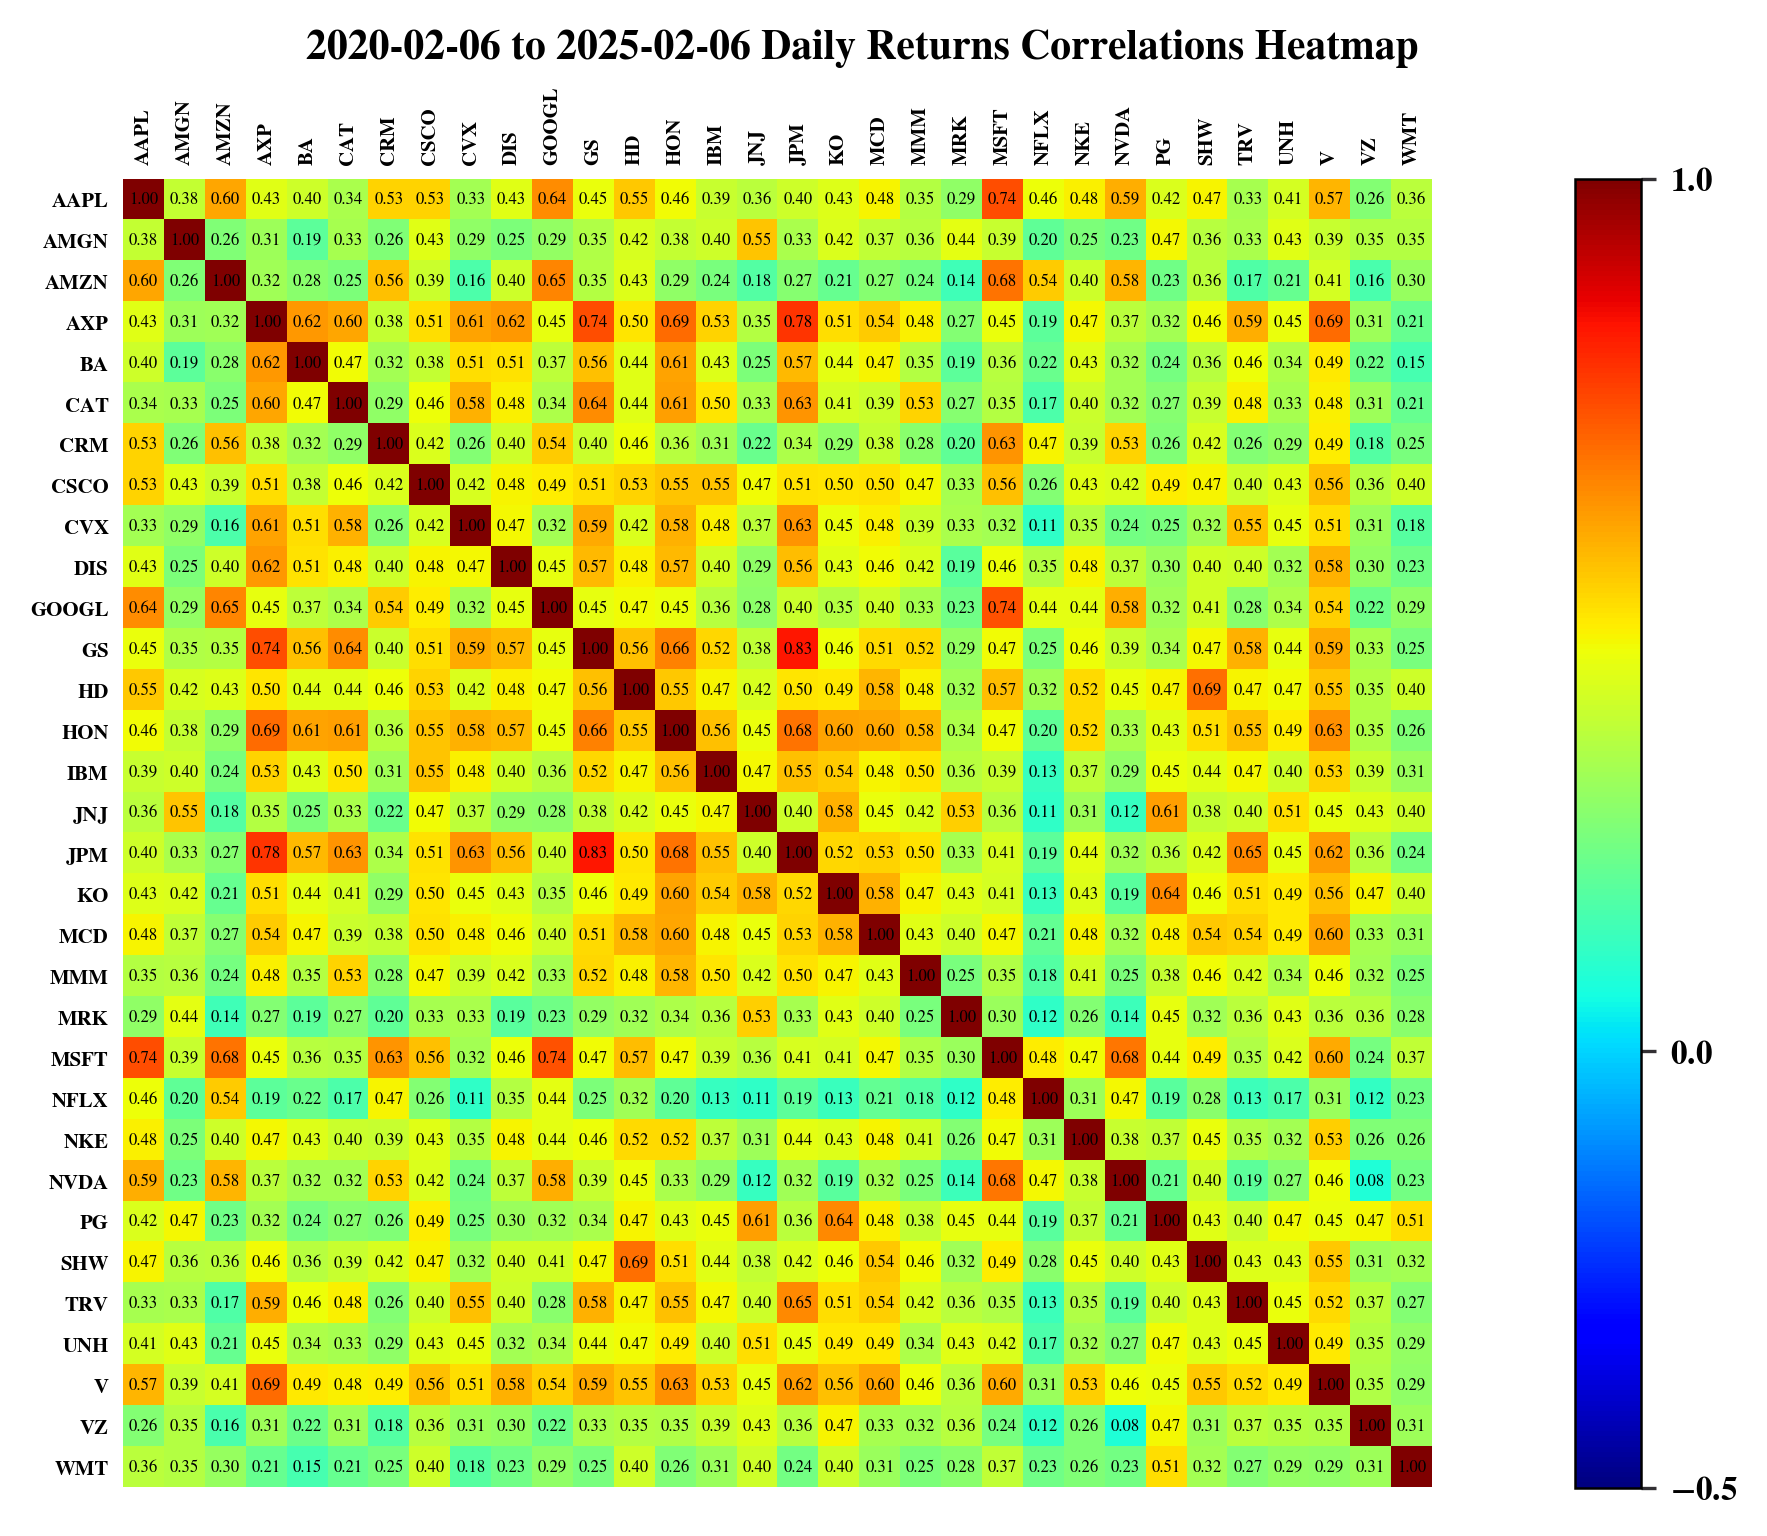

In [12]:
start_date = "2020-02-06"
end_date = "2025-02-06"
daily_returns = merged_correlation_matrix[f"{start_date}_{end_date}"]
plot_daily_return_heatmap(daily_returns, start_date, end_date)

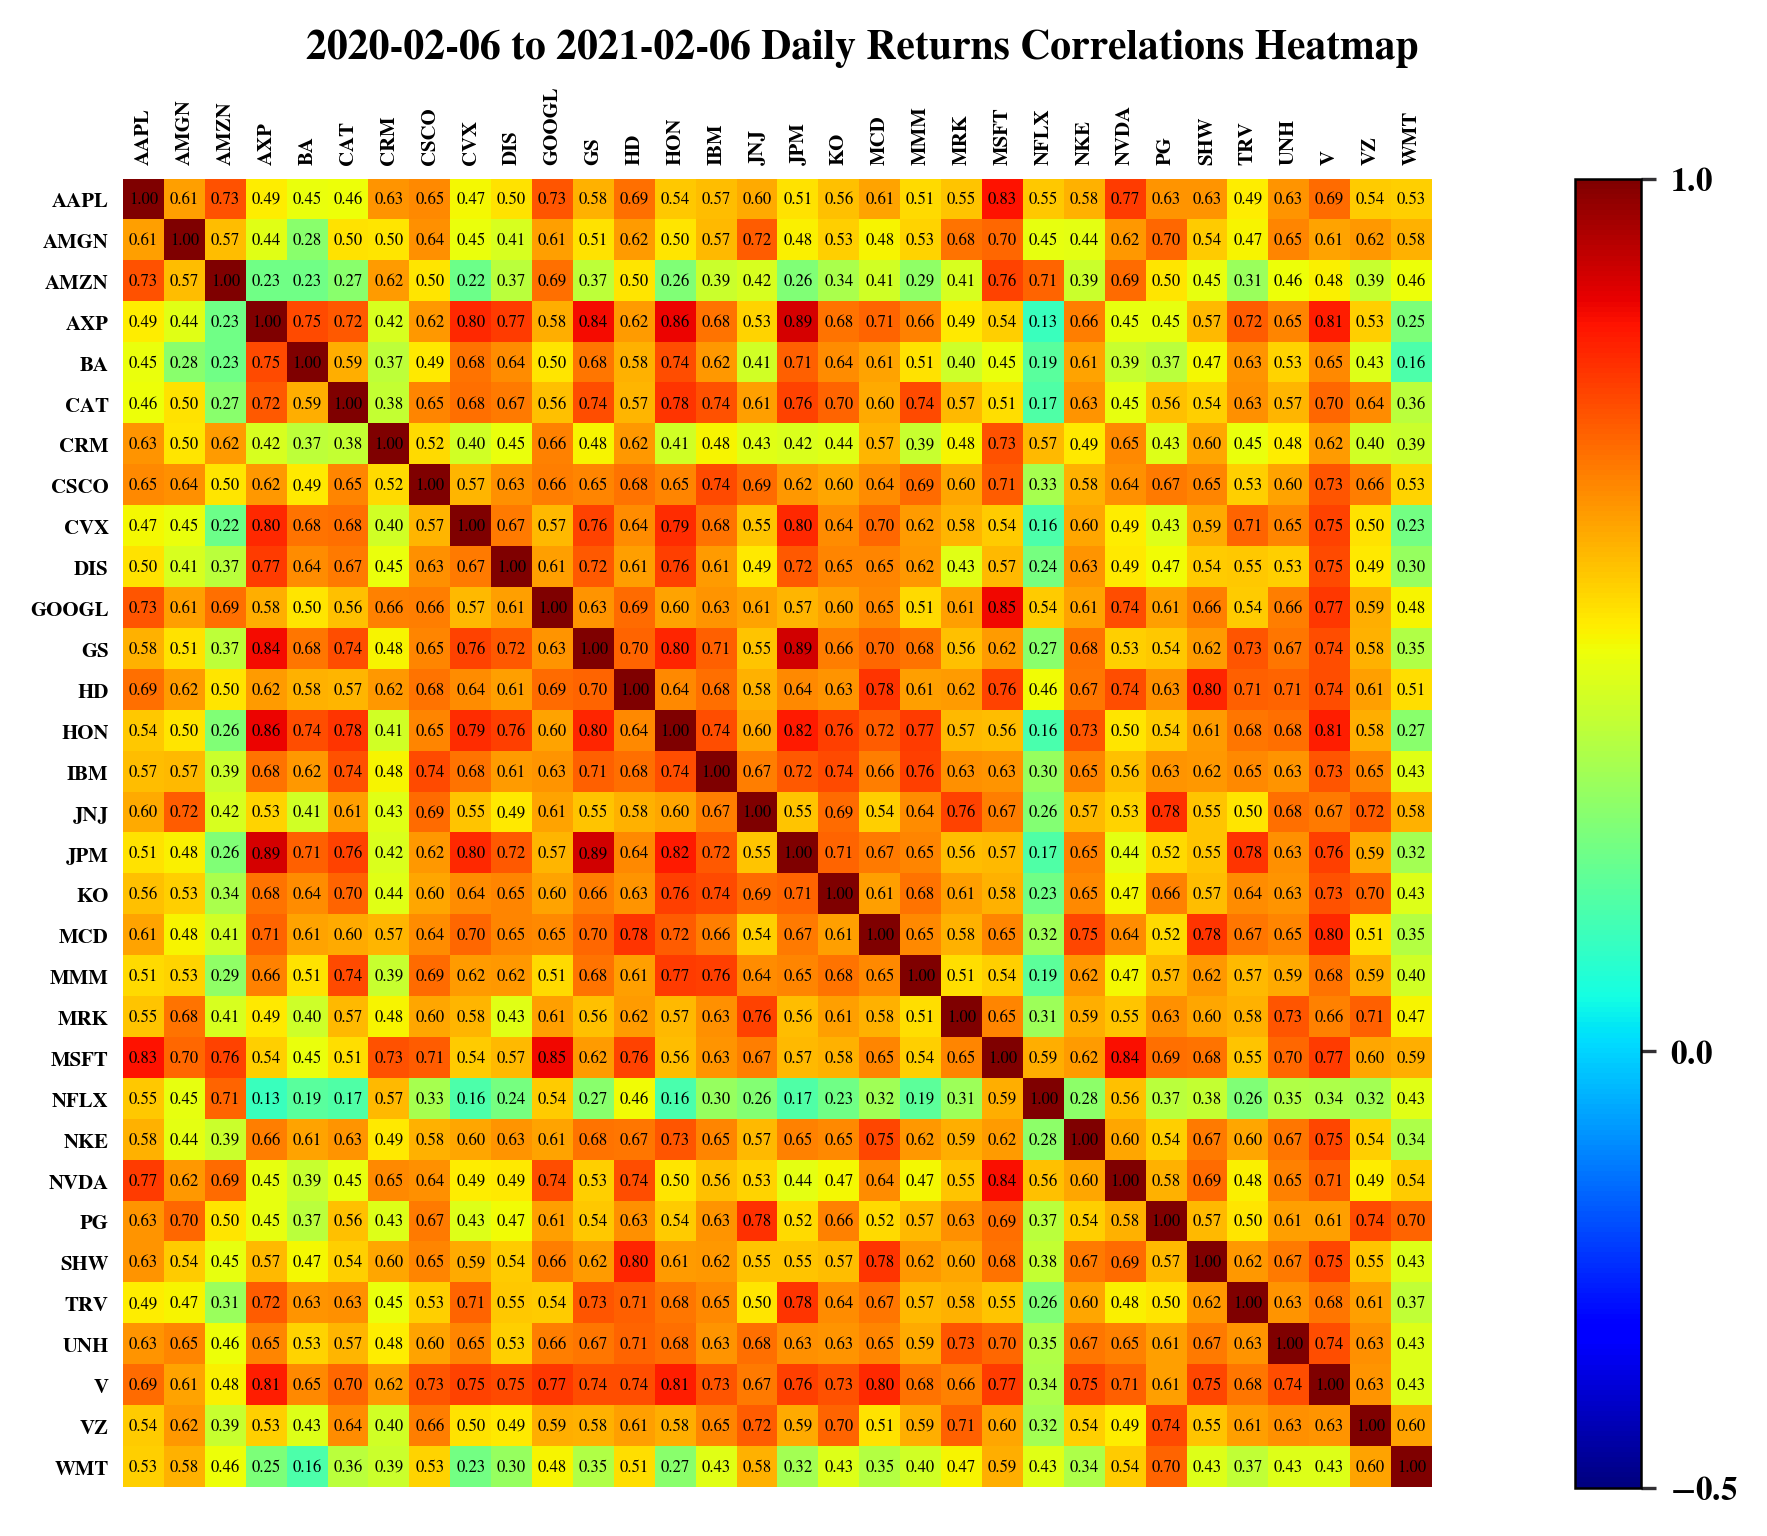

In [13]:
start_date = "2020-02-06"
end_date = "2021-02-06"
daily_returns = merged_correlation_matrix[f"{start_date}_{end_date}"]
plot_daily_return_heatmap(daily_returns, start_date, end_date)

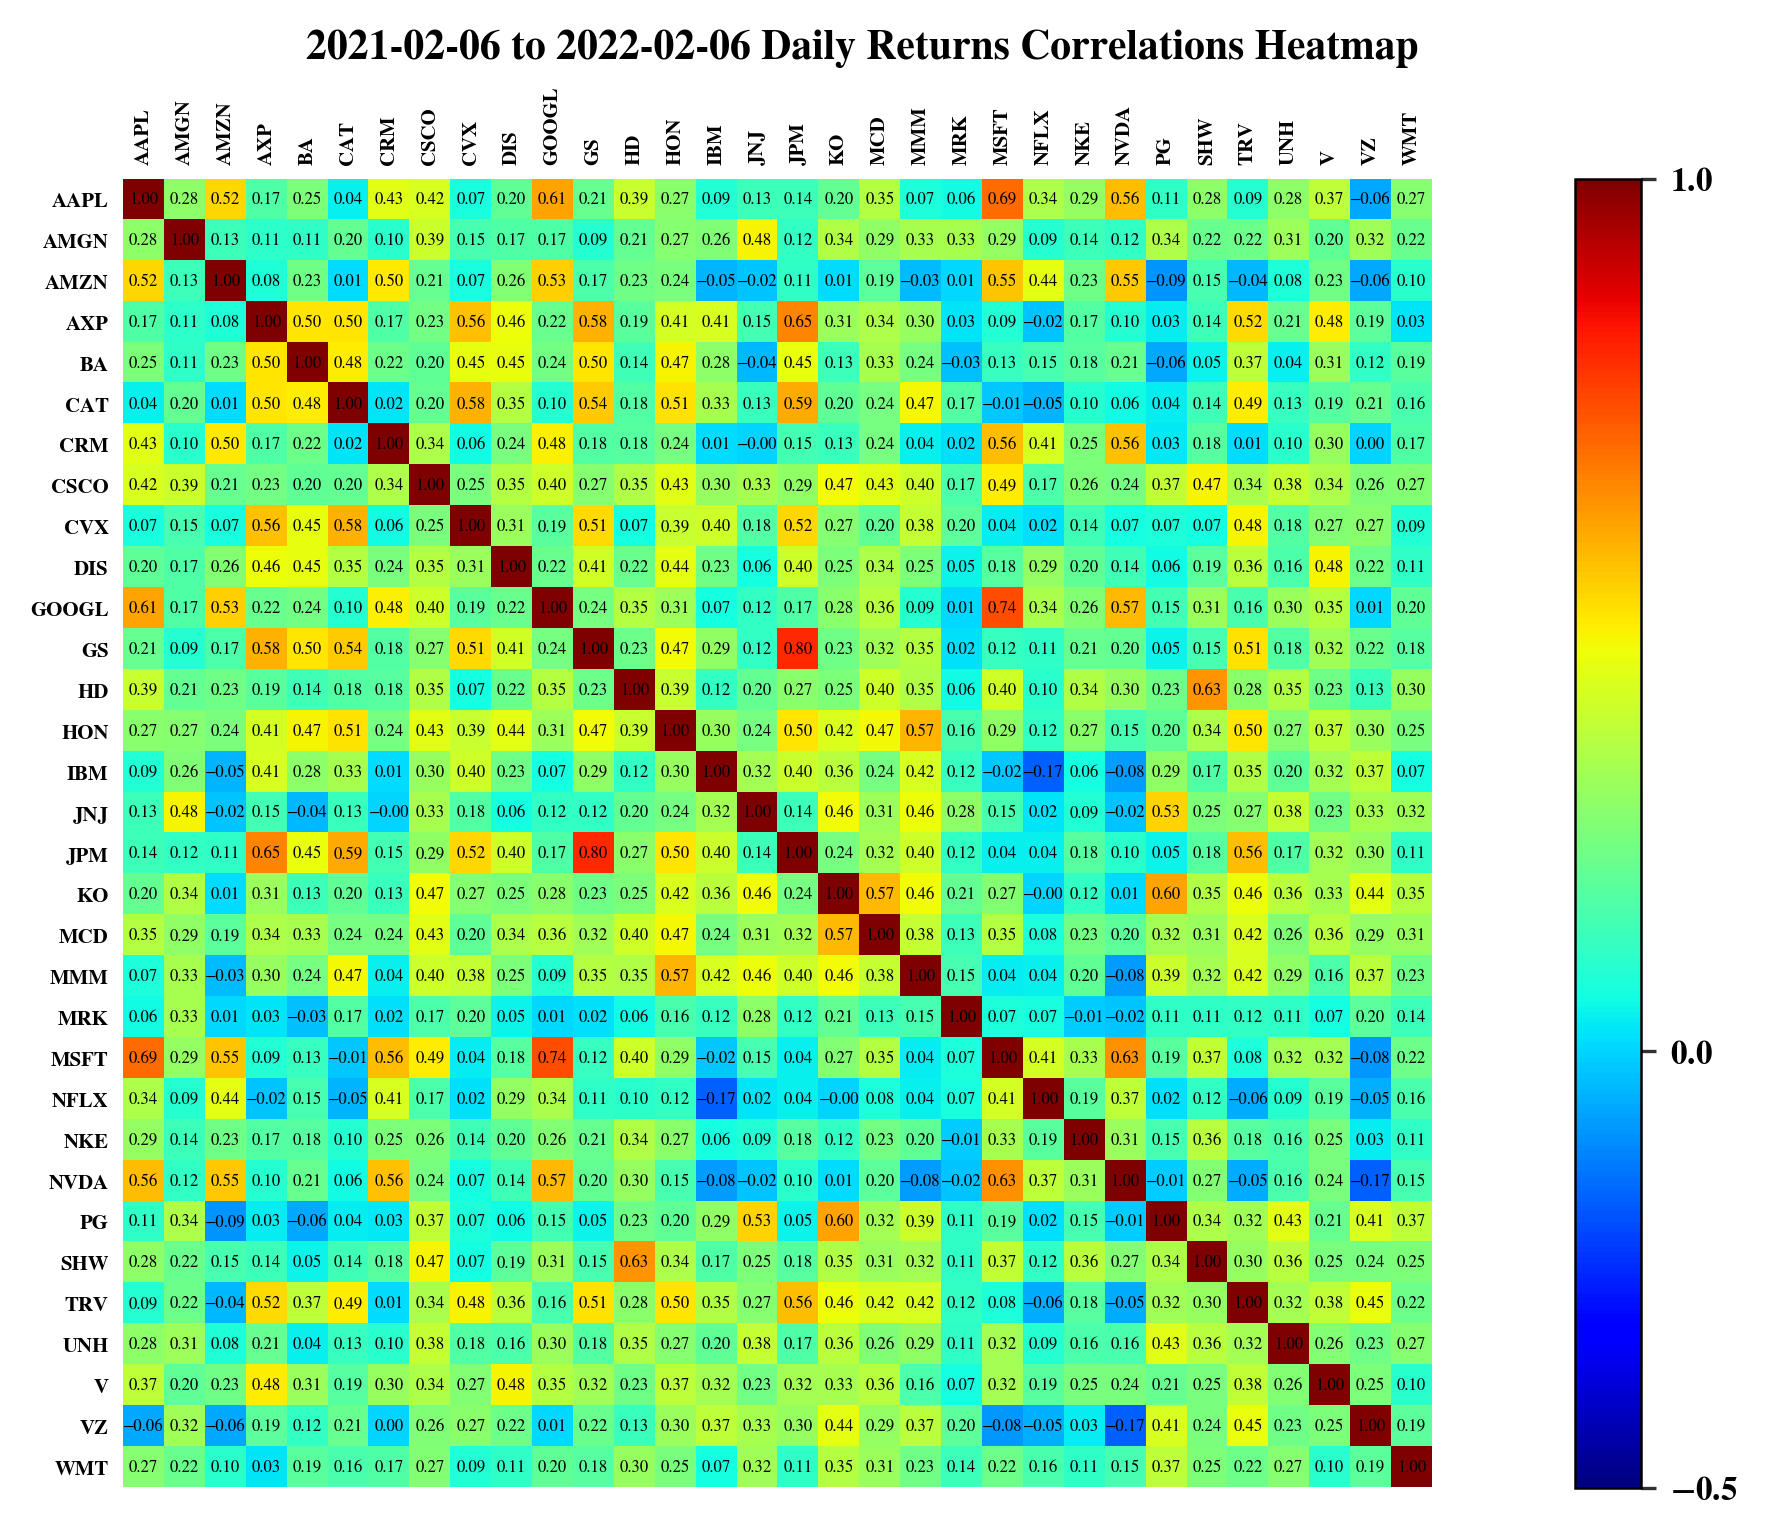

In [14]:
start_date = "2021-02-06"
end_date = "2022-02-06"
daily_returns = merged_correlation_matrix[f"{start_date}_{end_date}"]
plot_daily_return_heatmap(daily_returns, start_date, end_date)

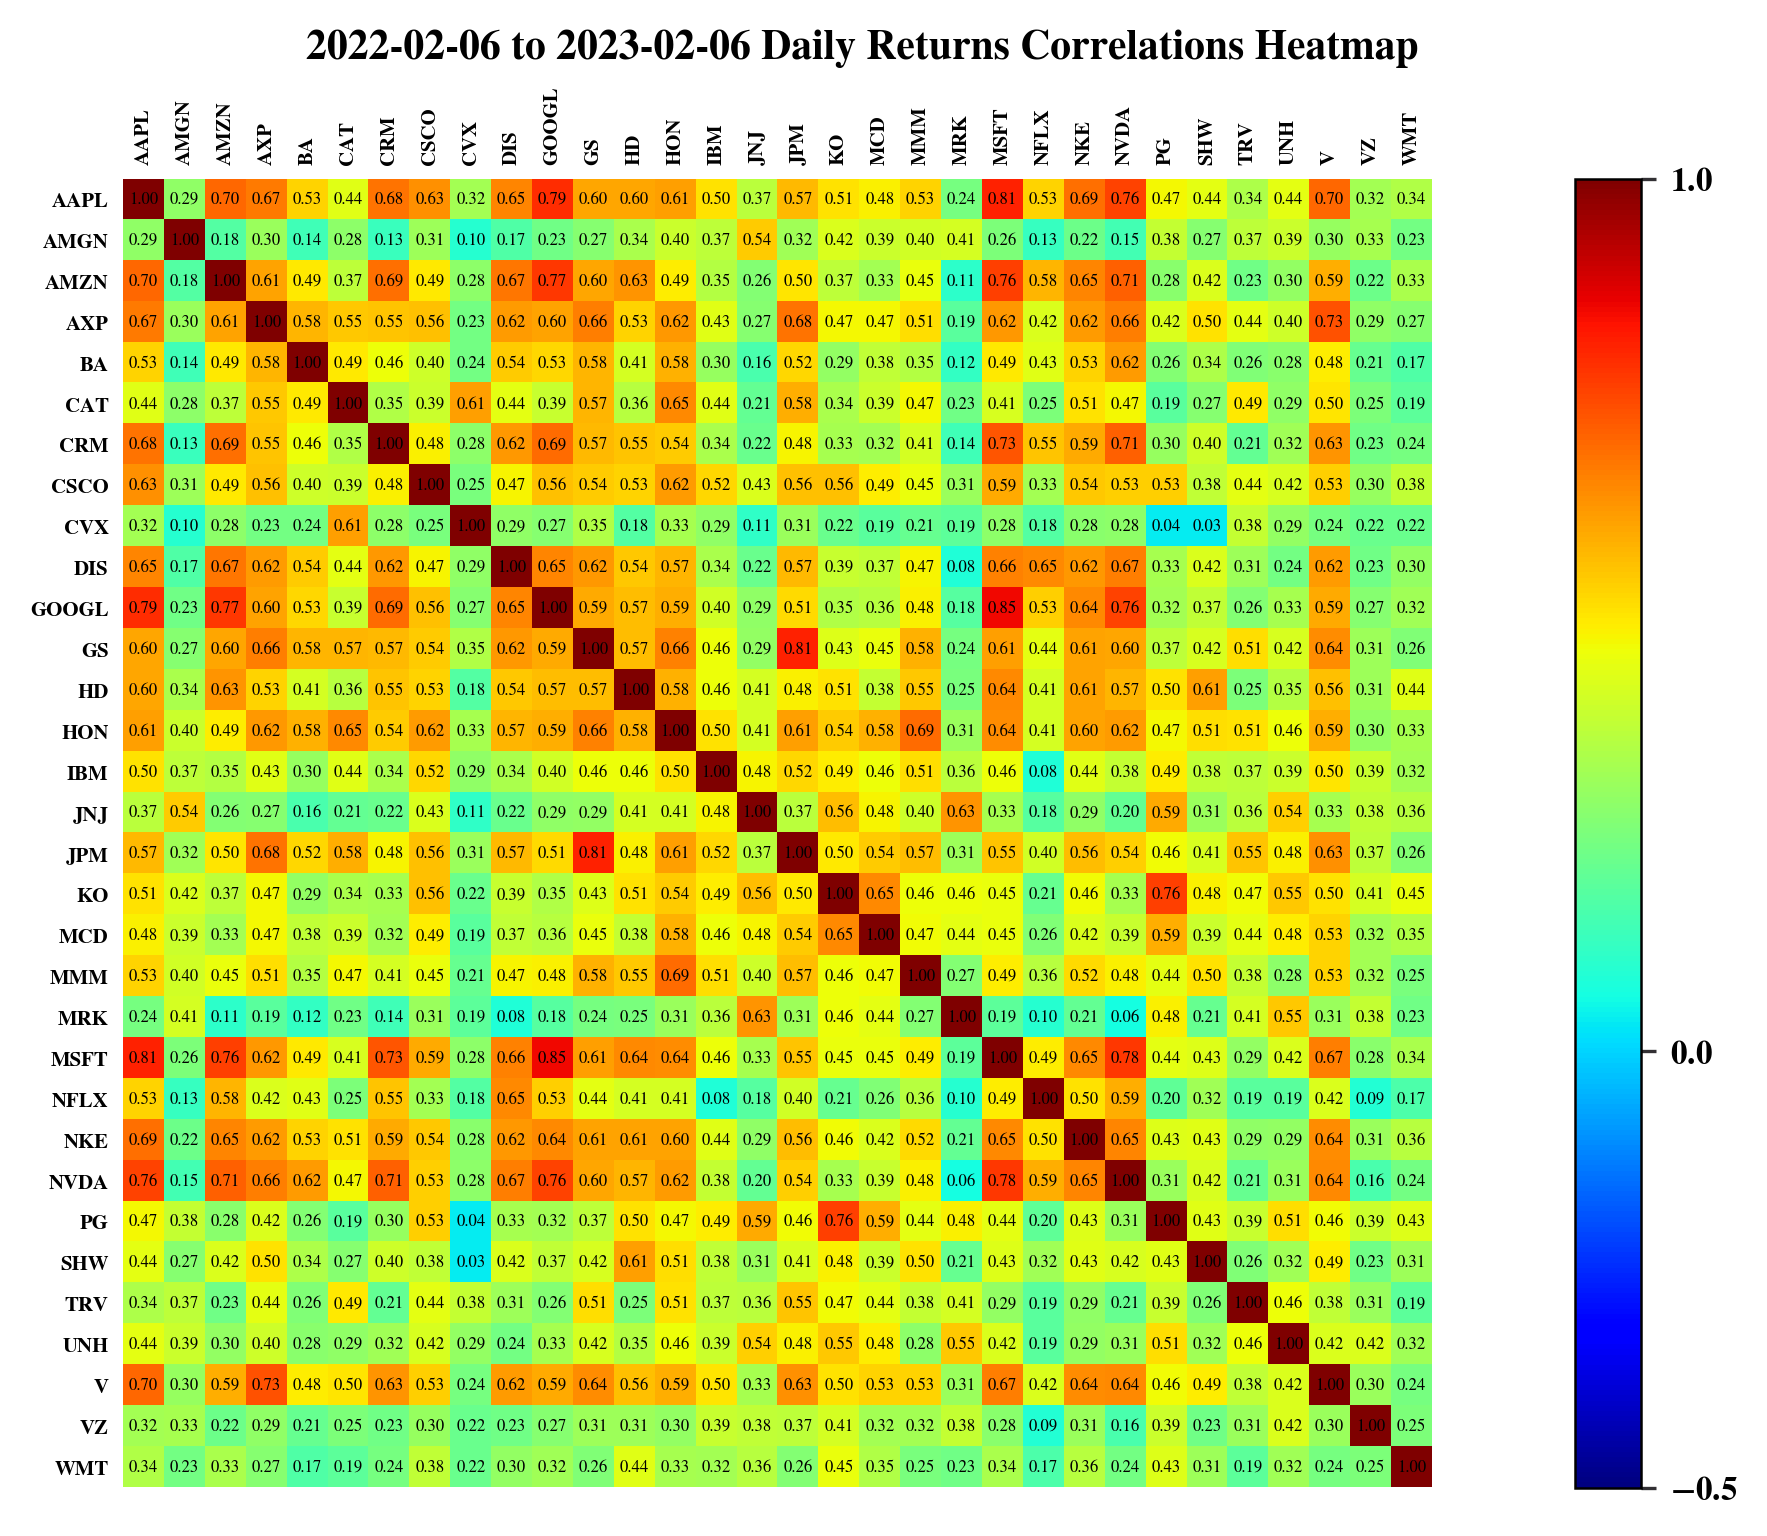

In [15]:
start_date = "2022-02-06"
end_date = "2023-02-06"
daily_returns = merged_correlation_matrix[f"{start_date}_{end_date}"]
plot_daily_return_heatmap(daily_returns, start_date, end_date)

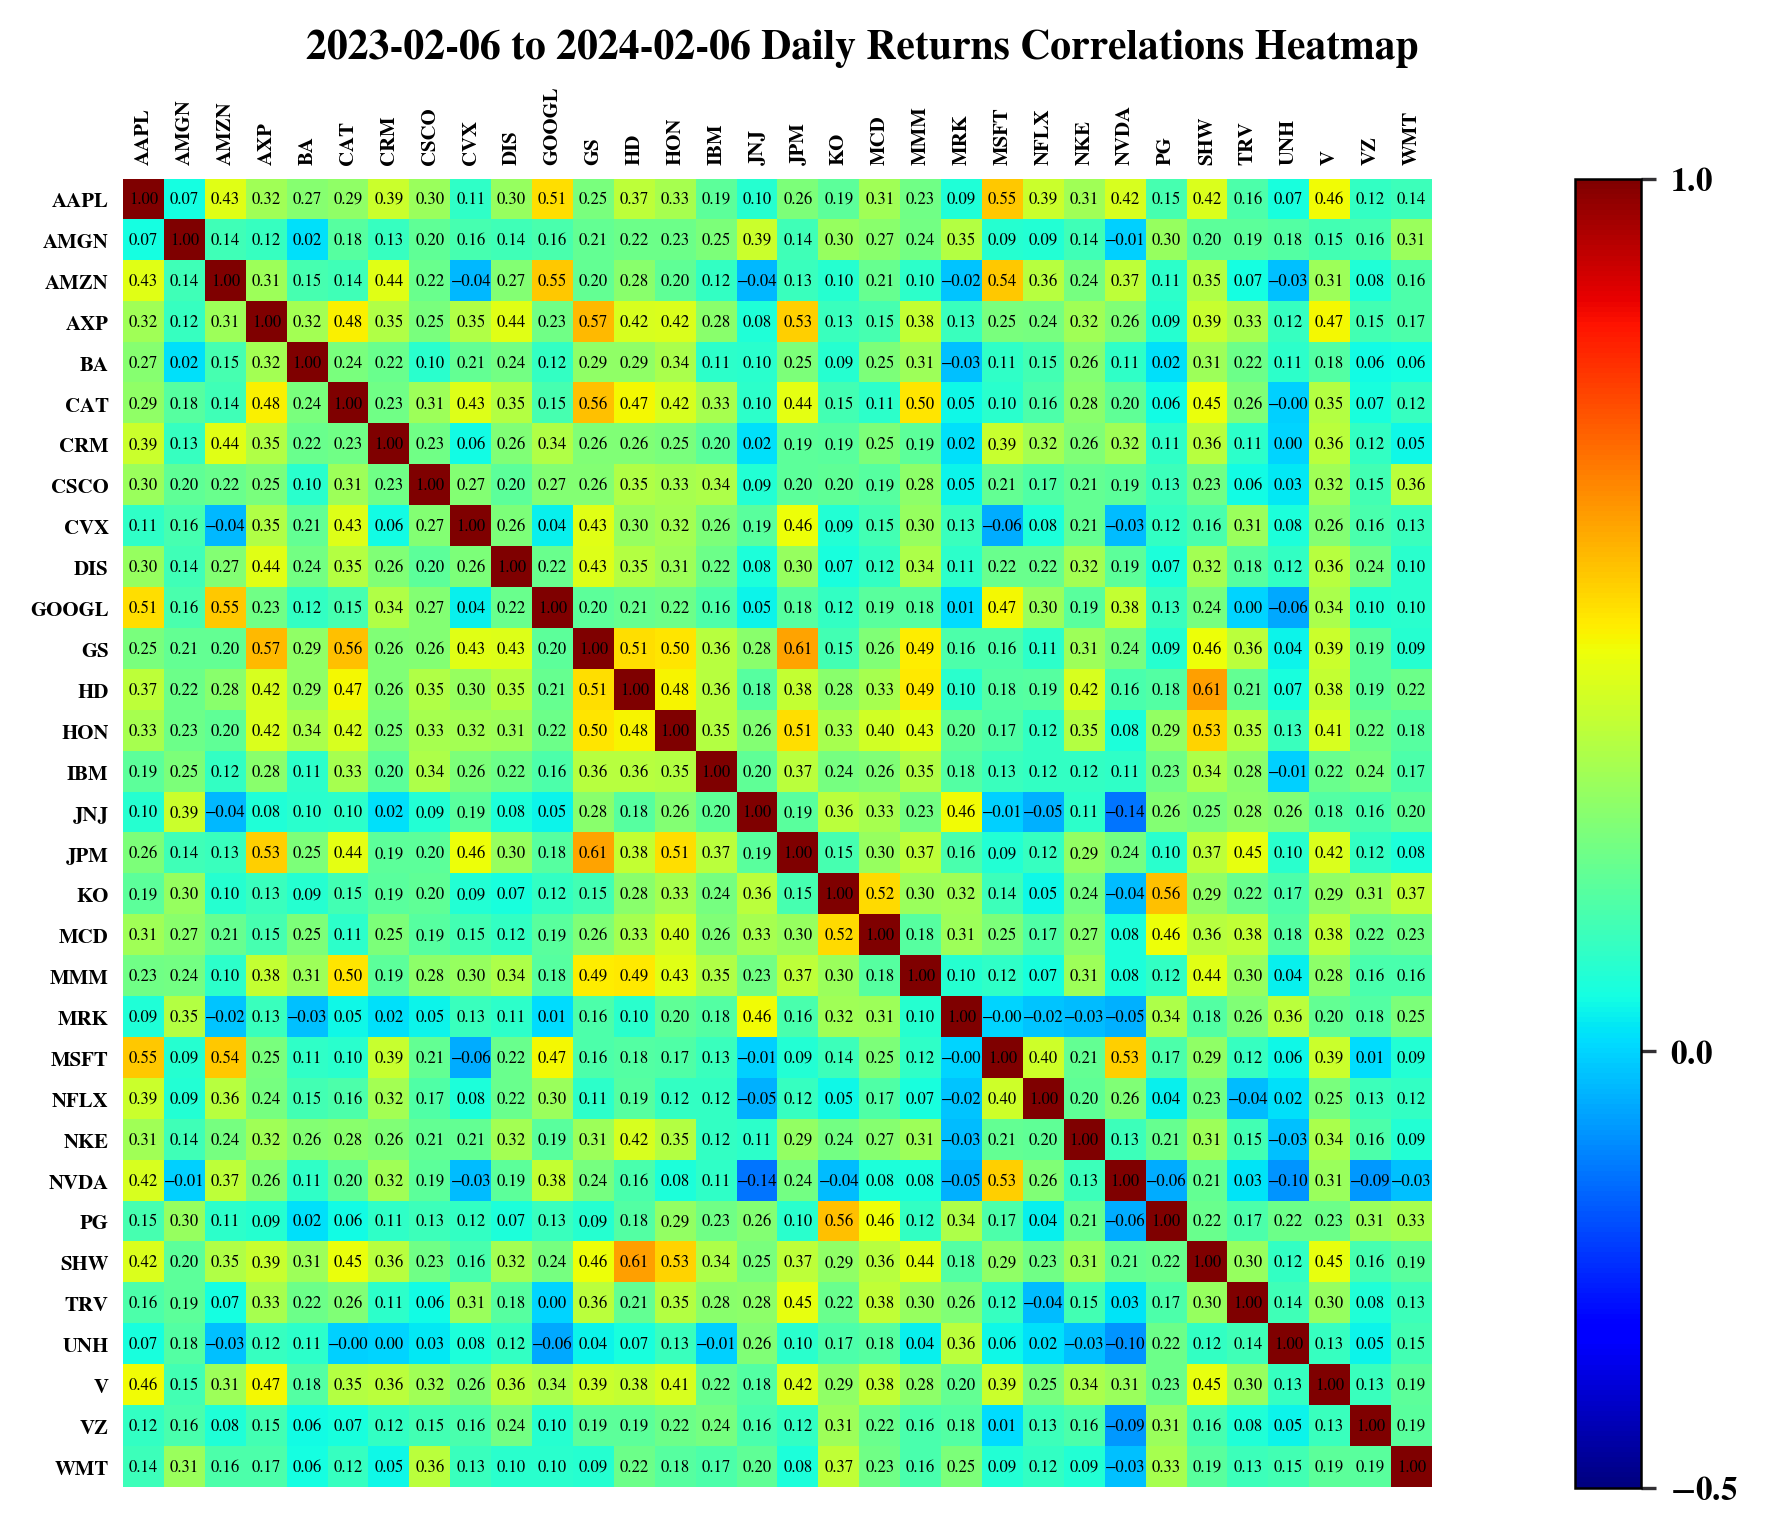

In [16]:
start_date = "2023-02-06"
end_date = "2024-02-06"
daily_returns = merged_correlation_matrix[f"{start_date}_{end_date}"]
plot_daily_return_heatmap(daily_returns, start_date, end_date)

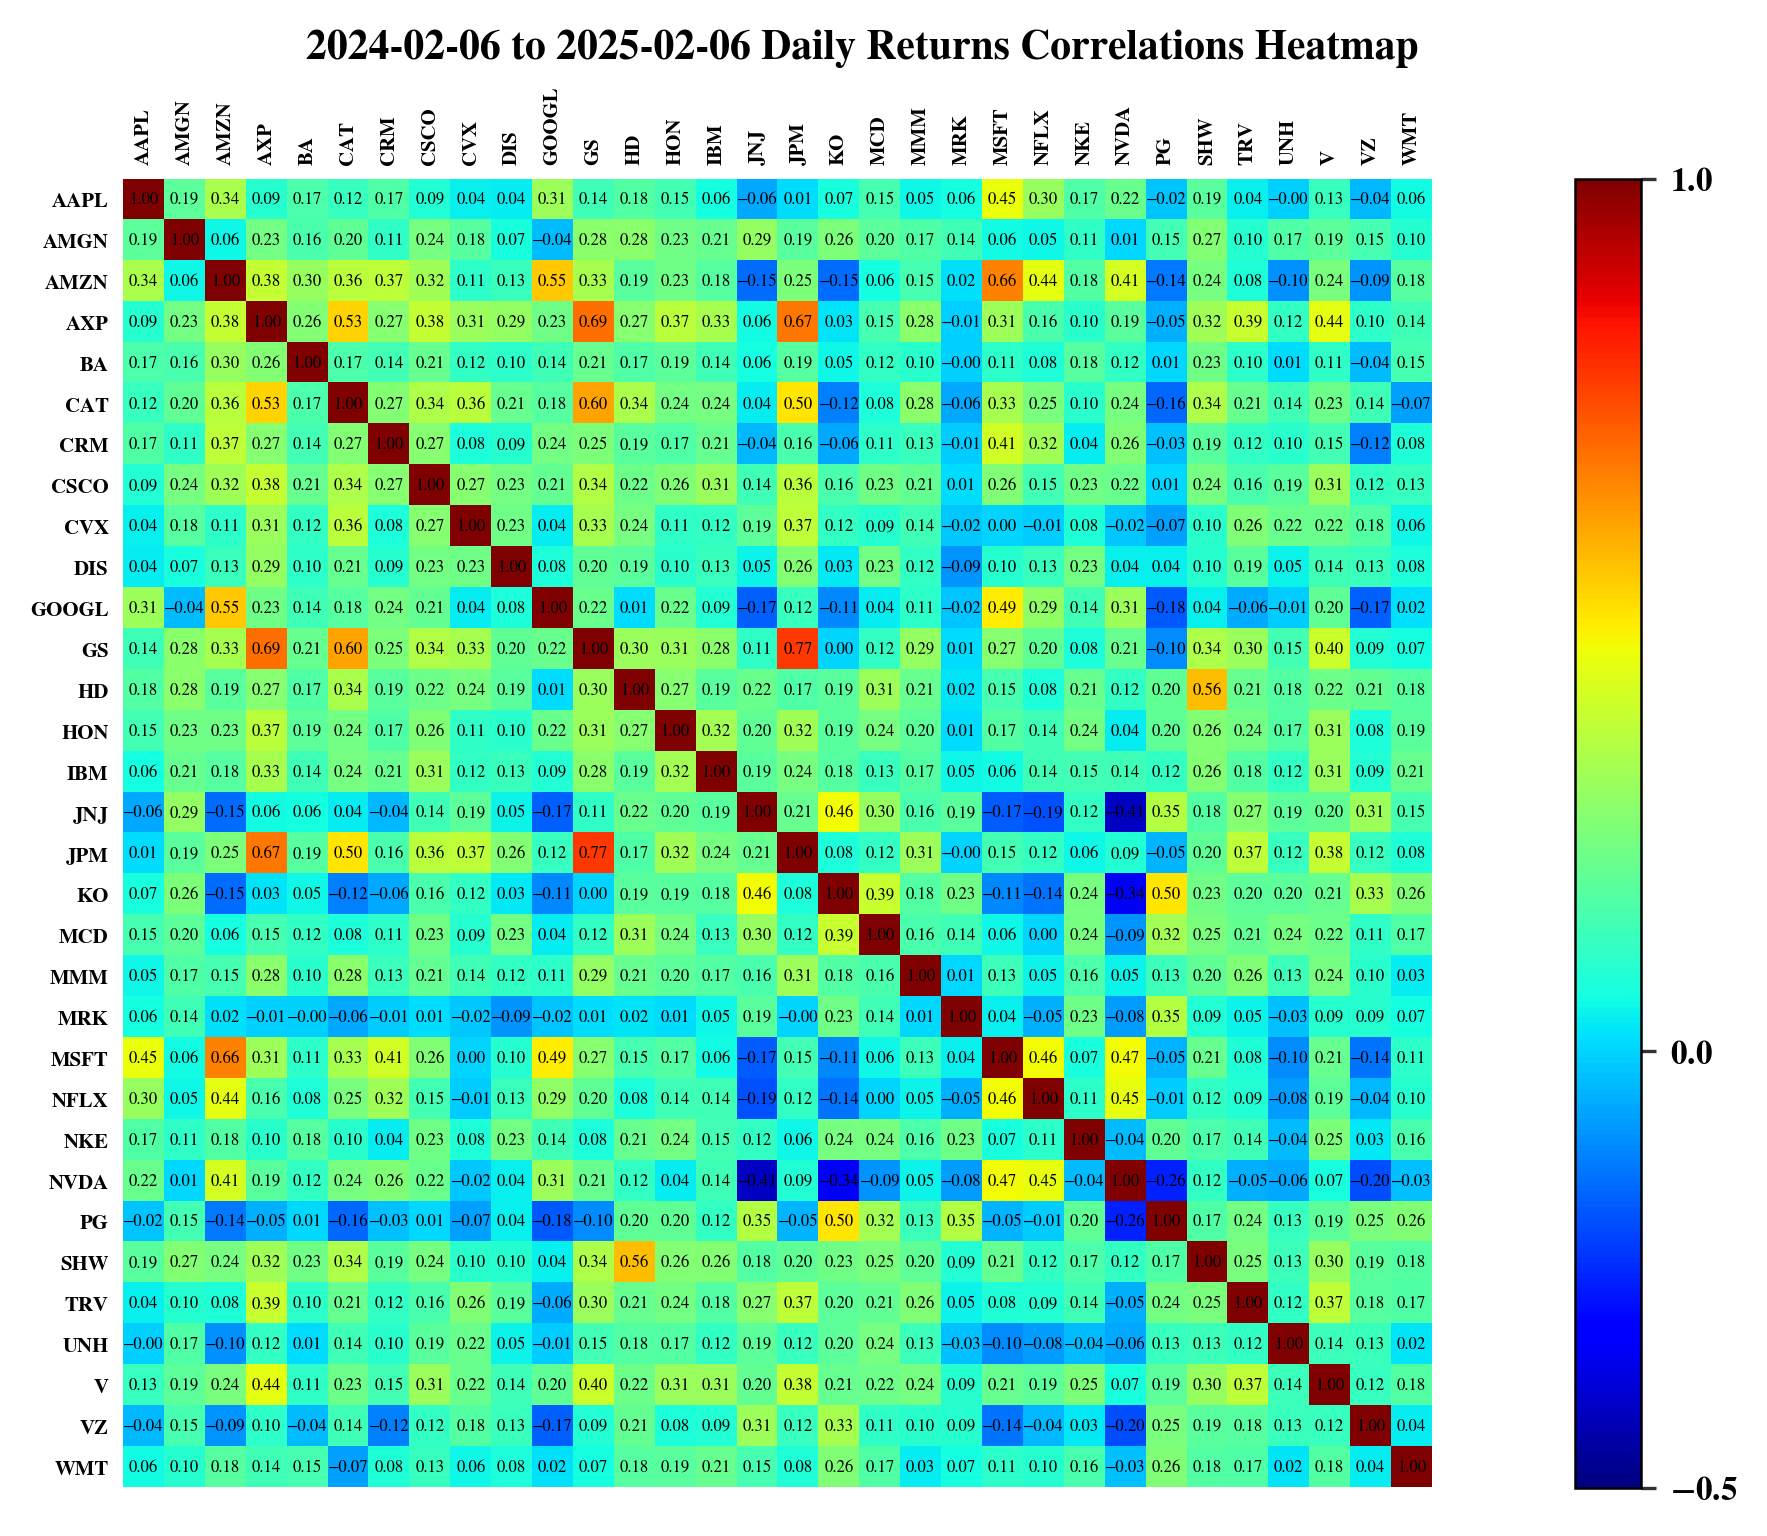

In [17]:
start_date = "2024-02-06"
end_date = "2025-02-06"
daily_returns = merged_correlation_matrix[f"{start_date}_{end_date}"]
plot_daily_return_heatmap(daily_returns, start_date, end_date)